# 응용 07. Optimizer·Dropout 비교와 최적 모델 복원

2026-10-30 실습 기록 · 원본: `../07_project.py`


## 0. 준비와 목적
pandas와 IPython이 설치된 커널에서 위에서 아래로 실행합니다. 이 노트북은 저장된 결과 CSV·PNG를 읽어 분석하므로 학습을 재실행하거나 결과 파일을 덮어쓰지 않습니다. 원본 학습 실행에는 PyTorch·Matplotlib도 필요합니다.

실습 목표는 Optimizer와 Dropout 비교, 최소 valid loss 모델의 복원, 클래스별 Recall 계산, 검증 표본별 예측 저장입니다. test는 학습·설정 선택에 사용하지 않습니다.

## 1. 비교 조건
| 후보 | Optimizer | Dropout p | lr |
| --- | --- | ---: | ---: |
| sgd | SGD(momentum=0) | 0 | 0.01 |
| adamw | AdamW | 0 | 0.01 |
| adamw_dropout | AdamW | 0.3 | 0.01 |

SGD와 AdamW를 비교할 때는 Dropout을 0으로 고정하고, Dropout 효과는 두 AdamW 후보끼리 비교합니다. 공통 학습률이 각 Optimizer의 최적 학습률이라는 뜻은 아닙니다.

공통 조건: 입력 2 → 은닉 32 → 은닉 32 → 출력 2, ReLU, BN 없음, weight_decay=0, batch_size=32, 40 epochs, 모델 seed=42, shuffle seed=43. 후보마다 모델·Optimizer·DataLoader를 새로 만듭니다. train 240건, valid 80건이며 마지막 학습 batch는 16건입니다. 원본은 CUDA 사용 가능 여부에 따라 장치를 선택합니다.


In [1]:
from pathlib import Path
import pandas as pd

candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / "20261030" / "02_응용"]
base = next((p for p in candidates if (p / "07_project.py").is_file()), None)
if base is None:
    raise FileNotFoundError("저장소 루트, 02_응용 또는 docs에서 실행하세요.")
base = base.resolve()
out = base / "outputs"
summary = pd.read_csv(out / "07_comparison.csv")
print(summary[["name", "best_epoch", "best_valid_loss", "valid_acc_at_best",
               "last_valid_loss", "restored_valid_loss", "restored_matches_best"]]
      .to_string(index=False, float_format=lambda x: f"{x:.6f}"))


         name  best_epoch  best_valid_loss  valid_acc_at_best  last_valid_loss  restored_valid_loss  restored_matches_best
          sgd          40         0.428053           0.800000         0.428053             0.428053                   True
        adamw          38         0.016560           1.000000         0.020212             0.016560                   True
adamw_dropout          40         0.036936           0.987500         0.036936             0.036936                   True


## 2. A07·A08: 학습과 평가
학습 batch마다 `optimizer.zero_grad()` → forward와 loss 계산 → `loss.backward()` → `optimizer.step()` 순서로 수행합니다. 이전 기울기를 비우고 현재 loss의 기울기로 한 번 갱신합니다.

각 epoch 학습 전 `model.train()`으로 Dropout을 활성화하고, epoch 종료 후 `model.eval()`과 `torch.no_grad()`로 train·valid 손실을 평가합니다. `eval()`은 모듈의 동작 모드, `no_grad()`는 연산의 기울기 기록을 제어합니다.

`train_loss_eval`은 학습 중 Dropout을 적용한 batch 손실이 아니라, epoch 말 Dropout을 끈 모델이 train 자료에서 얻은 손실입니다. valid는 가중치 갱신에 사용하지 않고 모델 선택에 사용합니다.


## 3. A09: best 모델을 독립적으로 보관하고 복원
초깃값은 `best_loss=float("inf")`, `best_epoch=0`, `best_state=None`입니다. 각 epoch의 검증 손실이 기존 최솟값보다 낮을 때만 세 값을 함께 갱신합니다.

원본에 기록한 설명:

```python
# 해설 A09: 현재 모델의 검증 손실이 지금까지의 최솟값보다 낮을 때만 세 값을 함께 갱신합니다.
# valid 데이터는 모델 선택에 사용하며, 이 블록에서 역전파나 가중치 학습을 수행하지 않습니다.
if valid_loss < best_loss:  # 엄격한 < 비교이므로 손실이 같으면 먼저 발견한 epoch를 유지합니다.
    best_loss = valid_loss  # 새 최소 검증 손실을 저장해 다음 epoch의 비교 기준으로 사용합니다.
    best_epoch = epoch  # 최소 손실을 기록한 현재 epoch 번호도 함께 보관합니다.
    # state_dict()에는 가중치·편향 등 파라미터와 BN running 통계 같은 버퍼가 들어갑니다.
    # state_dict()만 대입하면 내부 Tensor가 현재 모델과 저장소를 공유할 수 있어,
    # 이후 optimizer.step() 등으로 모델이 바뀔 때 보관한 최적 상태도 바뀔 수 있습니다.
    best_state = copy.deepcopy(model.state_dict())  # Tensor까지 독립적으로 복사해 이 시점의 상태를 고정합니다.
    # 학습 종료 후 model.load_state_dict(best_state)로 이 상태를 복원합니다.
    # 메모리에 보관하는 복사본이며, 모델 파일로 저장하려면 별도의 torch.save()가 필요합니다.
```

`<`를 사용하므로 동률이면 앞 epoch를 유지합니다. `state_dict()`에는 가중치·편향과 버퍼가 들어가며, `deepcopy`는 이후 학습의 변경을 받지 않는 독립 상태를 만듭니다.

학습 종료 후 `model.load_state_dict(best_state)`로 복원하고 `eval()`로 예측합니다. `restored_valid_loss`와 `best_loss`의 차이가 1e-6 미만인지 `restored_matches_best`로 기록합니다. **표에서 best epoch를 찾는 것만으로는 최적 가중치가 복원되지 않습니다.**

현재 모델 상태는 메모리에 보관하며 별도 `.pt` 모델 파일은 저장하지 않습니다. CSV·PNG 저장과 모델 가중치 파일 저장은 다릅니다. 전체 40 epochs를 수행하므로 Early Stopping도 아닙니다.


## 4. 실제 비교 결과
| 후보 | best epoch | best valid loss | best valid accuracy | 마지막 valid loss |
| --- | ---: | ---: | ---: | ---: |
| SGD | 40 | 0.428053 | 80.00% | 0.428053 |
| AdamW | 38 | 0.016560 | 100.00% | 0.020212 |
| AdamW + Dropout 0.3 | 40 | 0.036936 | 98.75% | 0.036936 |

근거는 `07_comparison.csv`와 후보별 `07_*_history.csv`입니다. 기본 AdamW가 이번 조건에서 가장 낮은 검증 손실을 기록했습니다. Dropout 추가가 개선을 보장하지 않으며, 단일 seed·작은 데이터·고정된 학습률의 결과를 일반적인 순위로 해석하지 않습니다.

AdamW는 38→40 epoch에서 train 손실이 0.018079→0.016876으로 감소하고 valid 손실은 증가해 과적합 가능성과 일치합니다. 다만 짧은 구간의 변화라 단정하기 어렵습니다. 다른 두 후보는 마지막 epoch가 best이므로 관찰 범위 안에서 best 이후 변화를 평가할 수 없습니다. 이후에도 계속 개선될지는 추가 실험이 필요합니다.


## 5. A10: 클래스별 support·correct·Recall
| 변수 | 계산과 의미 |
| --- | --- |
| labels | valid의 실제 정답을 CPU로 이동 |
| best_pred | 복원한 모델의 logits에서 argmax로 선택한 예측 클래스, CPU로 이동 |
| mask | `labels == label`: 실제 정답이 현재 클래스인 위치 |
| support | mask의 True 개수: 해당 클래스의 실제 표본 수 |
| correct | mask로 선택한 표본 중 예측도 현재 클래스인 개수 |
| recall | correct / support, support가 0이면 None |
| class_rows | 각 클래스의 label·support·correct·recall을 담은 딕셔너리 목록 |

`for label in (0, 1)`로 클래스마다 한 번만 계산합니다. `for label in labels`는 표본마다 반복해 클래스 결과가 중복됩니다. `label`만 append하면 지표가 저장되지 않으므로 결과 딕셔너리를 append합니다.

```python
mask = labels == label  # 실제 정답이 현재 클래스인 위치
support = mask.sum().item()  # 해당 표본 수를 Python 숫자로 변환
correct = (best_pred[mask] == label).sum().item()  # 그중 예측까지 맞힌 수
recall = correct / support if support > 0 else None  # 실제 표본 중 맞힌 비율
class_rows.append({"label": label, "support": support,
                   "correct": correct, "recall": recall})
```

Recall의 분모는 **해당 클래스의 실제 표본 수**입니다. 예측이 해당 클래스인 표본 수를 분모로 쓰면 Precision이며, 전체 표본 수를 쓰면 클래스별 Recall이 아닙니다.


In [2]:
metric_tables = []
for name in summary["name"]:
    metrics = pd.read_csv(out / f"07_{name}_class_metrics.csv")
    metrics.insert(0, "name", name)
    metric_tables.append(metrics)
print(pd.concat(metric_tables, ignore_index=True).to_string(index=False))


         name  label  support  correct  recall
          sgd      0       40       32   0.800
          sgd      1       40       32   0.800
        adamw      0       40       40   1.000
        adamw      1       40       40   1.000
adamw_dropout      0       40       39   0.975
adamw_dropout      1       40       40   1.000


## 6. 표본별 예측 저장과 결과 검증
`07_{후보}_predictions.csv`에는 검증 표본마다 `id`(표본 식별자), `actual`(실제 정답), `predicted`(복원한 best 모델의 예측 클래스)를 기록합니다. 실제 요청 로그가 아닌 검증 자료의 표본별 예측입니다. 확률이나 logits는 현재 CSV에 저장하지 않습니다.

아래는 후보별 80건 여부, 예측에서 다시 계산한 클래스별 지표, history의 최소 손실과 복원 손실의 일치를 확인합니다.


In [3]:
for name in summary["name"]:
    predictions = pd.read_csv(out / f"07_{name}_predictions.csv")
    metrics = pd.read_csv(out / f"07_{name}_class_metrics.csv")
    history = pd.read_csv(out / f"07_{name}_history.csv")
    result = summary.loc[summary["name"] == name].iloc[0]
    assert len(predictions) == 80
    assert abs(history["valid_loss"].min() - result["restored_valid_loss"]) < 1e-6
    assert result["restored_matches_best"]
    for row in metrics.itertuples():
        selected = predictions[predictions["actual"] == row.label]
        assert len(selected) == row.support
        assert (selected["actual"] == selected["predicted"]).sum() == row.correct
        if row.support:
            assert abs(row.recall - row.correct / row.support) < 1e-8
        else:
            assert pd.isna(row.recall)
    print(f"{name}: 최적 복원·80건·클래스별 지표 일치 확인")
    print(predictions.head().to_string(index=False))


sgd: 최적 복원·80건·클래스별 지표 일치 확인
      id  actual  predicted
D10_0354       1          1
D10_0146       0          0
D10_0122       0          0
D10_0333       1          1
D10_0123       0          0
adamw: 최적 복원·80건·클래스별 지표 일치 확인
      id  actual  predicted
D10_0354       1          1
D10_0146       0          0
D10_0122       0          0
D10_0333       1          1
D10_0123       0          0
adamw_dropout: 최적 복원·80건·클래스별 지표 일치 확인
      id  actual  predicted
D10_0354       1          1
D10_0146       0          0
D10_0122       0          0
D10_0333       1          1
D10_0123       0          0


## 7. 후보별 학습곡선

실선은 epoch 말 eval 모드의 train·valid 손실이며, 점선은 최소 valid loss의 epoch입니다. 그림별 축 범위를 고려해 표의 수치와 함께 비교합니다.


sgd


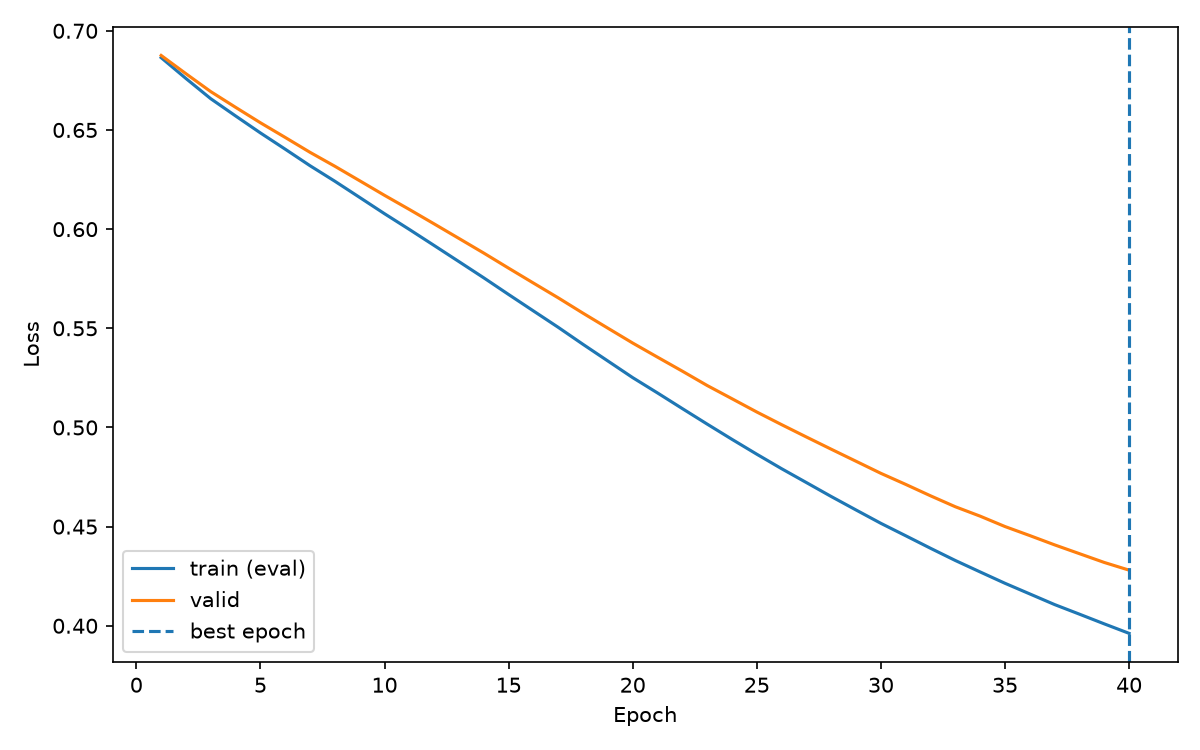

adamw


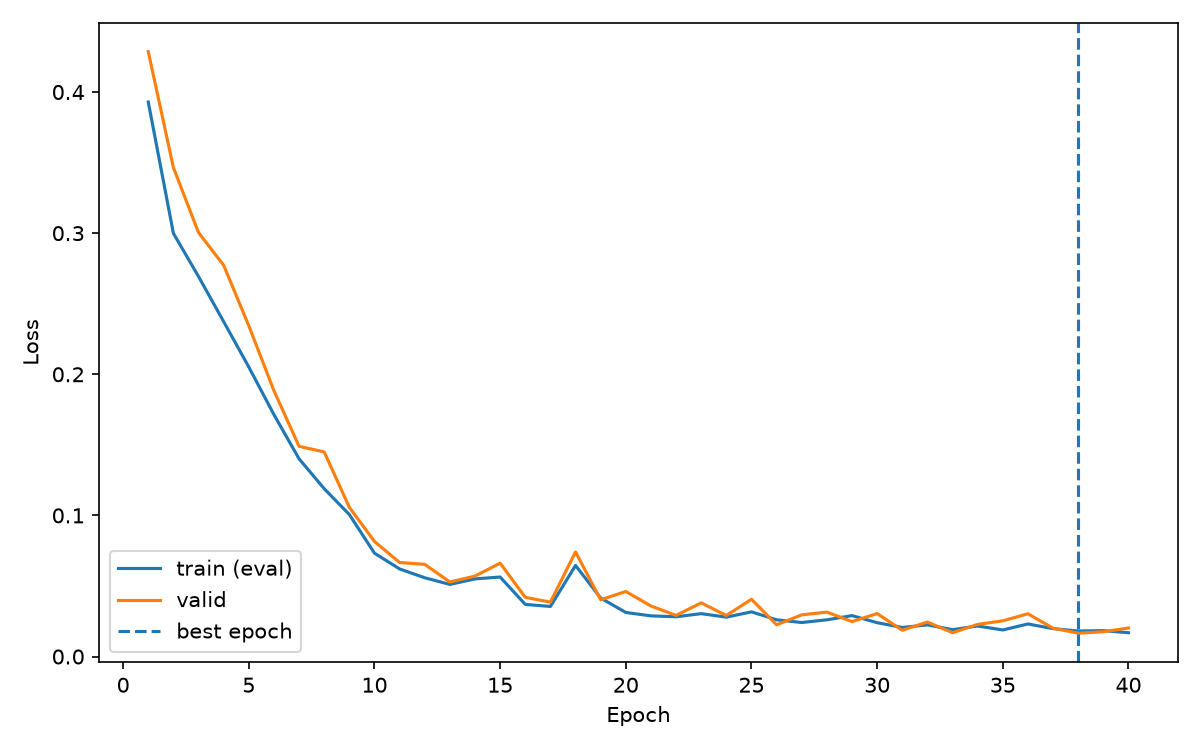

adamw_dropout


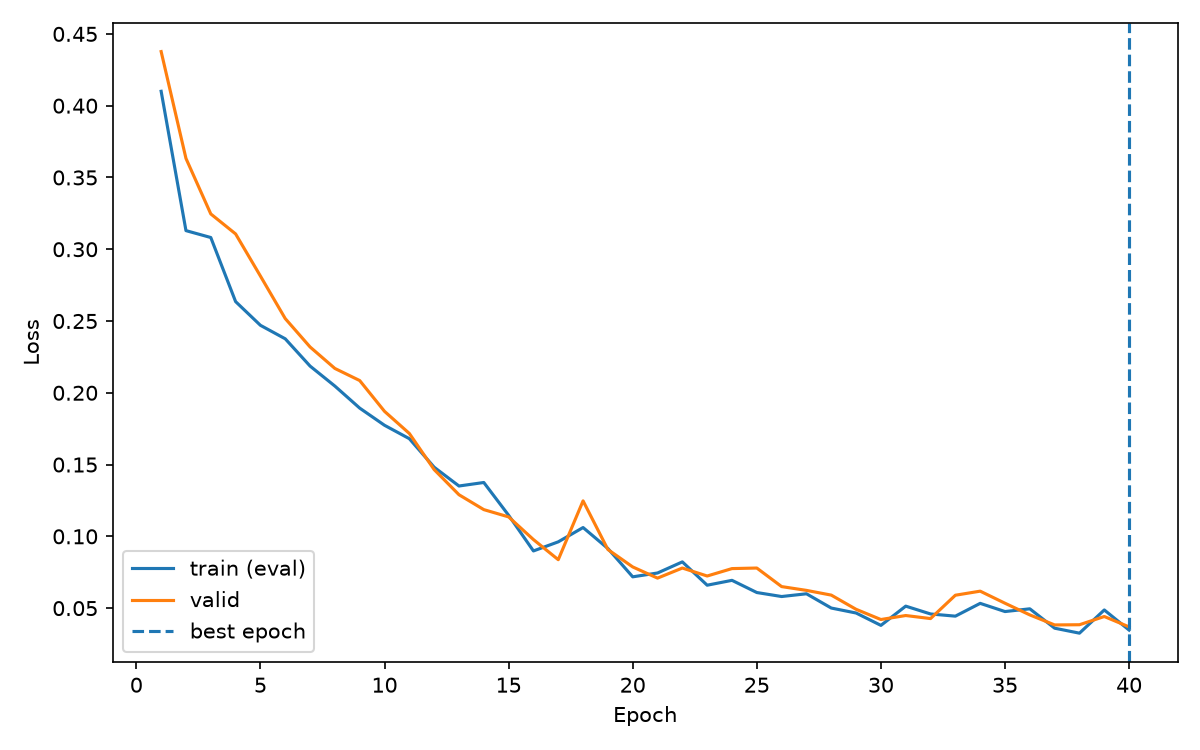

In [4]:
from IPython.display import Image, display
for name in summary["name"]:
    print(name)
    display(Image(filename=str(out / f"07_{name}_curves.png")))


## 8. 저장 결과와 한계
- `07_comparison.csv`: 후보별 best epoch·loss, 복원 loss·일치 여부
- `07_{후보}_history.csv`: epoch별 train_loss_eval·valid_loss·valid_acc
- `07_{후보}_class_metrics.csv`: 클래스별 label·support·correct·recall
- `07_{후보}_predictions.csv`: 검증 표본별 id·actual·predicted
- `07_{후보}_curves.png`: 학습곡선

최적 복원 후 얻은 예측으로 지표를 계산해야 저장된 결과가 최적 모델의 평가를 의미합니다. 이번 기록은 기존 실행 결과이며, 여러 seed 반복이나 최종 test 평가는 수행하지 않았습니다.
